# Polinomsal (Doğrusal Olmayan) Regresyon ile Ayakkabı Numarası Tahmini

Bu çalışma kitabında, `ayakkabi_numarasi.xlsx` veri kümesinde yer alan **Kilo(kg)**, **Boy(metre)**, **Yaş** ve **Cinsiyet(E veya K)** bağımsız değişkenleri kullanılarak hedef değişken olan **Ayakkabı Numarası**nı tahmin eden doğrusal olmayan bir **Polinomsal Regresyon (Polynomial Regression)** modeli adım adım inşa edilecektir.

### İşlem Akışı Adımları:
1. **Kütüphanelerin Yüklenmesi**
2. **Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)**
3. **Veri Ön İşleme (Data Preprocessing)**
4. **Eğitim ve Test Kümelerine Ayırma**
5. **Doğrusal Olmayan Modelin Eğitilmesi (Polinomsal Regresyon)**
6. **Modelin Değerlendirilmesi**
7. **Örnek Girdilerle Yeni Tahmin Yapma**

## 1. Gerekli Kütüphanelerin Yüklenmesi
Veri analizi, modelleme ve metrik hesaplamaları için gerekli kütüphaneleri içe aktarıyoruz. Özellikleri doğrusal olmayan karesel forma dönüştürmek için `PolynomialFeatures` kullanacağız.

In [10]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import PolynomialFeatures
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

# Grafik ayarları
sns.set_theme(style="whitegrid")
plt.rcParams['figure.figsize'] = (8, 5)

## 2. Veri Setinin Yüklenmesi ve Keşifsel Veri Analizi (EDA)
Excel dosyasından veriyi okuyor, ilk satırları ve özet istatistikleri inceliyoruz.

In [11]:
# Excel dosyasını okuma
df = pd.read_excel('ayakkabi_numarasi.xlsx')

# İlk 5 satırı görüntüleme
print("--- İlk 5 Satır ---")
display(df.head())

# İstatiksel özet
print("\n--- İstatiksel Özet ---")
display(df.describe())

--- İlk 5 Satır ---


,Kilo(kg),Boy(metre),Yaş,Cinsiyet(E veya K),Ayakkabı Numarası
0,85,1.74,42,E,41
1,44,1.40,10,E,36
2,32,1.38,11,E,36
3,48,1.46,11,E,37
4,75,1.62,47,E,42



--- İstatiksel Özet ---


,Kilo(kg),Boy(metre),Yaş,Ayakkabı Numarası
count,58.000000,58.000000,58.000000,58.000000
mean,53.827586,1.569655,29.534483,37.913793
std,22.639151,0.157335,21.961062,3.326051
min,5.000000,1.100000,6.000000,28.000000
25%,39.000000,1.490000,11.000000,36.000000
50%,48.500000,1.560000,16.500000,38.000000
75%,70.250000,1.650000,43.000000,40.750000
max,110.000000,1.870000,82.000000,45.000000


Cinsiyet Dağılımı:
Cinsiyet(E veya K)
E    31
K    27
Name: count, dtype: int64


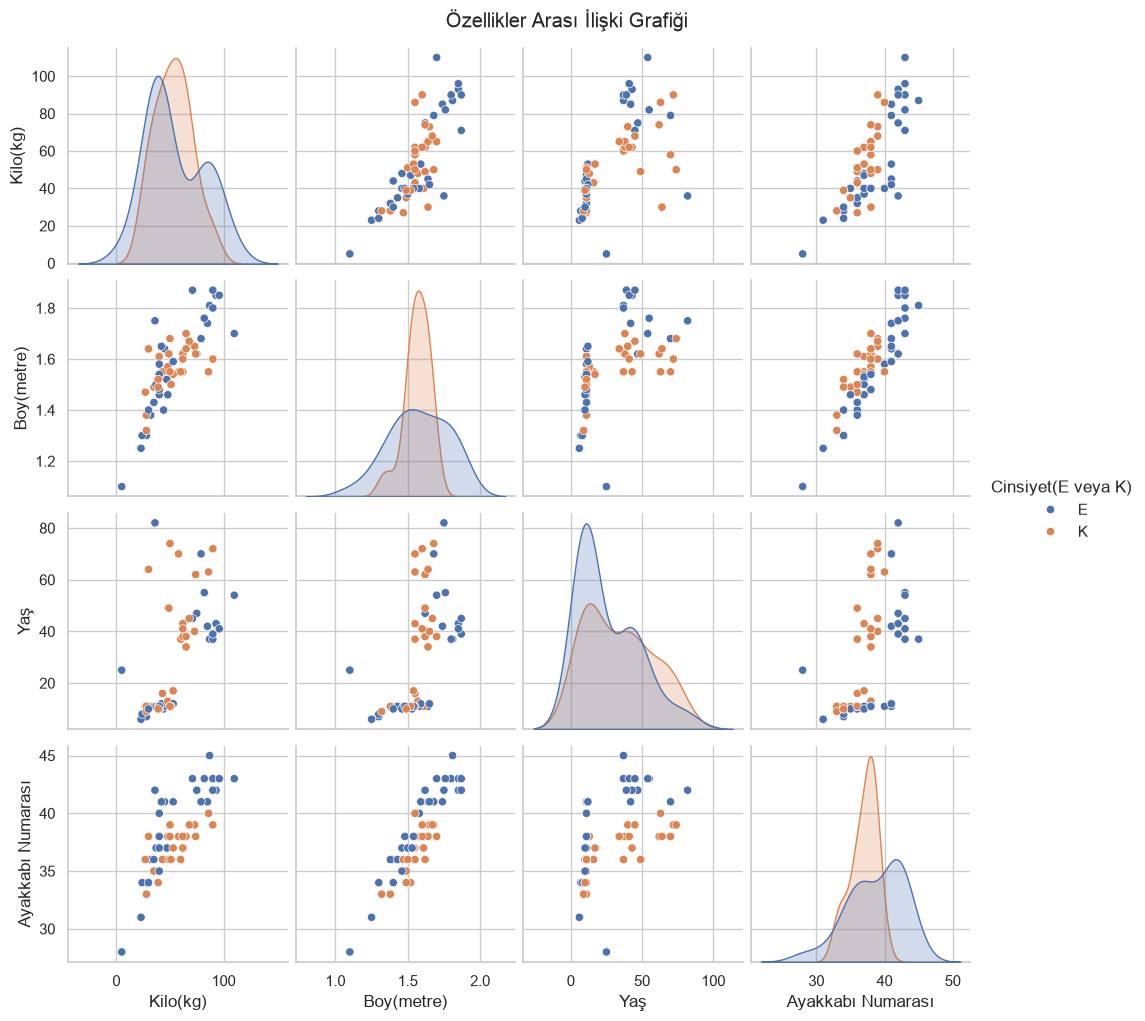

In [12]:
# Cinsiyet dağılımı
print("Cinsiyet Dağılımı:")
print(df['Cinsiyet(E veya K)'].value_counts())

# Özellikler arasındaki ilişkilerin görselleştirilmesi
sns.pairplot(df, hue='Cinsiyet(E veya K)', diag_kind='kde')
plt.suptitle("Özellikler Arası İlişki Grafiği", y=1.02)
plt.show()

## 3. Veri Ön İşleme (Data Preprocessing)
Makine öğrenmesi modelleri sayısal girdiler kabul eder. Bu aşamada:
- `Cinsiyet(E veya K)` sütunundaki metinsel değerleri ikili (binary) formata dönüştürüyoruz (`E = 1`, `K = 0`).
- Bağımsız değişken matrisini ($X$) ve bağımlı hedef vektörünü ($y$) ayrıştırıyoruz.

In [13]:
# Cinsiyet sütununu ikili sayısal formata kodlama (E: 1, K: 0)
df['Cinsiyet_E'] = (df['Cinsiyet(E veya K)'] == 'E').astype(int)

# Bağımsız değişkenler (X) ve bağımlı değişken (y)
feature_cols = ['Kilo(kg)', 'Boy(metre)', 'Yaş', 'Cinsiyet_E']
X = df[feature_cols]
y = df['Ayakkabı Numarası']

print("X Şekli:", X.shape)
print("y Şekli:", y.shape)
X.head()

X Şekli: (58, 4)
y Şekli: (58,)


,Kilo(kg),Boy(metre),Yaş,Cinsiyet_E
0,85,1.74,42,1
1,44,1.40,10,1
2,32,1.38,11,1
3,48,1.46,11,1
4,75,1.62,47,1


## 4. Eğitim ve Test Kümelerine Ayırma
Modelin daha önce görmediği veriler üzerindeki genelleme başarısını test etmek için veriyi %80 Eğitim, %20 Test olarak ikiye bölüyoruz.

In [14]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print(f"Eğitim seti boyutu: {X_train.shape[0]} örnek")
print(f"Test seti boyutu:   {X_test.shape[0]} örnek")

Eğitim seti boyutu: 46 örnek
Test seti boyutu:   12 örnek


## 5. Doğrusal Olmayan Modelin Eğitilmesi (Polinomsal Regresyon)
Standart doğrusal regresyonun kısıtlarını aşmak ve eğrisel ilişkileri modellemek için özellikleri 2. derece polinomsal forma (kareler ve etkileşimler) dönüştürüp eğitiyoruz.

In [15]:
# 2. Derece Polinomsal dönüştürücünün oluşturulması
poly_converter = PolynomialFeatures(degree=2, include_bias=False)

# Eğitim ve test verilerini polinomsal formata (eğrisel özelliklere) dönüştürme
X_train_poly = poly_converter.fit_transform(X_train)
X_test_poly = poly_converter.transform(X_test)

# Genişletilmiş bu özellikler üzerinden doğrusal regresyonu eğitme
model = LinearRegression()
model.fit(X_train_poly, y_train)

print("Polinomsal (Doğrusal Olmayan) model eğitimi tamamlandı.")

Polinomsal (Doğrusal Olmayan) model eğitimi tamamlandı.


## 6. Modelin Değerlendirilmesi
Test verisi üzerinde tahminler üreterek $R^2$, MAE (Ortalama Mutlak Hata) ve RMSE (Karekök Ortalama Kare Hata) metriklerini inceliyoruz.

In [16]:
# Test seti tahminleri
y_pred = model.predict(X_test_poly)

# Metriklerin hesaplanması
r2 = r2_score(y_test, y_pred)
mae = mean_absolute_error(y_test, y_pred)
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

print(f"R² Skoru (Açıklanan Varyans Oranı): {r2:.3f}")
print(f"MAE (Ortalama Mutlak Hata):        {mae:.2f} numara")
print(f"RMSE (Karekök Ortalama Kare Hata): {rmse:.2f} numara")

R² Skoru (Açıklanan Varyans Oranı): 0.531
MAE (Ortalama Mutlak Hata):        1.10 numara
RMSE (Karekök Ortalama Kare Hata): 1.23 numara


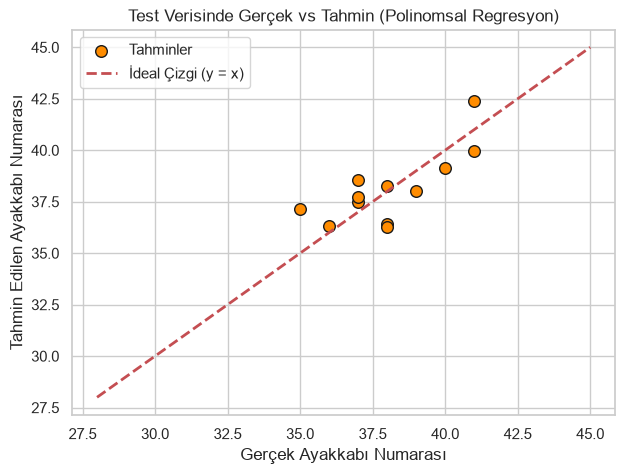

In [17]:
# Gerçek ve Tahmin Edilen Değerlerin Karşılaştırılması
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='darkorange', edgecolor='k', s=70, label='Tahminler')
plt.plot([y.min(), y.max()], [y.min(), y.max()], 'r--', lw=2, label='İdeal Çizgi (y = x)')
plt.xlabel('Gerçek Ayakkabı Numarası')
plt.ylabel('Tahmin Edilen Ayakkabı Numarası')
plt.title('Test Verisinde Gerçek vs Tahmin (Polinomsal Regresyon)')
plt.legend()
plt.show()

## 7. Örnek Girdilerle Yeni Tahmin Yapma
Eğitilmiş doğrusal olmayan (polinomsal) modeli kullanarak yeni bireyler için ayakkabı numarası tahmini üretiyoruz.

In [18]:
# Örnek yeni veri: [Kilo(kg), Boy(metre), Yaş, Cinsiyet_E (1: Erkek, 0: Kadın)]
yeni_ornekler = pd.DataFrame([
    {'Kilo(kg)': 78, 'Boy(metre)': 1.76, 'Yaş': 30, 'Cinsiyet_E': 1}, # Erkek
    {'Kilo(kg)': 56, 'Boy(metre)': 1.63, 'Yaş': 25, 'Cinsiyet_E': 0}  # Kadın
])

# Yeni verileri modele vermeden önce mutlaka polinomsal dönüşümden geçirmeliyiz!
yeni_ornekler_poly = poly_converter.transform(yeni_ornekler)
tahminler = model.predict(yeni_ornekler_poly)

for i, row in yeni_ornekler.iterrows():
    cinsiyet = 'Erkek' if row['Cinsiyet_E'] == 1 else 'Kadın'
    print(f"{cinsiyet} (Boy: {row['Boy(metre)']}m, Kilo: {row['Kilo(kg)']}kg, Yaş: {row['Yaş']}) -> "
          f"Tahmin: {tahminler[i]:.2f} (En Yakın No: {round(tahminler[i])})")

Erkek (Boy: 1.76m, Kilo: 78.0kg, Yaş: 30.0) -> Tahmin: 42.58 (En Yakın No: 43)
Kadın (Boy: 1.63m, Kilo: 56.0kg, Yaş: 25.0) -> Tahmin: 37.38 (En Yakın No: 37)
